# 🍄 Taller de Clustering — Parte 1: Setas

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## Fase 01 · Comprensión del problema y de los datos

**Problema:** ¿se agrupan *solas* las setas en comestibles y venenosas?

La columna `class` (`e` = comestible, `p` = venenosa) es la etiqueta. **El clustering no la usa**: la guardamos *solo para validar* al final.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

### Leer el conjunto de datos y primer vistazo

In [2]:
df = pd.read_csv("docs/workshop/data/mushrooms.csv")  # la tabla con todas las setas
print("Filas x columnas:", df.shape)
df.head()  # las 5 primeras filas

Filas x columnas: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración

In [3]:
# Con texto, describe() da: count (filas), unique (valores distintos),
# top (el más repetido) y freq (cuántas veces sale).
df.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


In [4]:
# Tipo de cada columna: todas salen 'str' (texto; en pandas antiguos sale 'object').
# Cada letra es un código, p. ej. en 'class': e = comestible, p = venenosa.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [5]:
# ¿Cuántas setas de cada clase? (solo para conocer los datos, no para agrupar)
df["class"].value_counts()

class
e    4208
p    3916
Name: count, dtype: int64

### Nulos

In [6]:
# Contar nulos por columna. Sale todo 0... pero ojo: los valores desconocidos
# pueden estar escritos como '?' (lo veremos en la fase 02).
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

> **Resumen fase 01:** 8124 setas × 23 columnas, **todas categóricas** (letras). Hay etiqueta (`class`), pero solo para validar. No hay nulos *aparentes*.

## Fase 02 · Preparación de los datos

**Objetivo:** dejar los datos limpios y en números, que es lo único que entienden los modelos.

### Buscar valores extraños: ¿cuántos valores distintos tiene cada columna?

In [7]:
n_values = pd.DataFrame({
    "feature": df.columns,                                  # nombre de cada columna
    "n_values": [df[col].nunique() for col in df.columns],  # cuántos valores distintos tiene
})
n_values.sort_values("n_values").head()  # de menos a más: lo raro sale arriba

,feature,n_values
16,veil-type,1
0,class,2
4,bruises,2
6,gill-attachment,2
7,gill-spacing,2


Nadie nos dice dónde están los problemas: miramos **todos** los valores de **todas** las columnas.

In [8]:
# Imprimimos los valores distintos de cada columna, ordenados.
# Buscamos a ojo algo que no sea una letra-código: '?', '-', 'NA', ''...
for col in df.columns:
    print(f"{col:26} {sorted(df[col].unique())}")

class                      ['e', 'p']
cap-shape                  ['b', 'c', 'f', 'k', 's', 'x']
cap-surface                ['f', 'g', 's', 'y']
cap-color                  ['b', 'c', 'e', 'g', 'n', 'p', 'r', 'u', 'w', 'y']
bruises                    ['f', 't']
odor                       ['a', 'c', 'f', 'l', 'm', 'n', 'p', 's', 'y']
gill-attachment            ['a', 'f']
gill-spacing               ['c', 'w']
gill-size                  ['b', 'n']
gill-color                 ['b', 'e', 'g', 'h', 'k', 'n', 'o', 'p', 'r', 'u', 'w', 'y']
stalk-shape                ['e', 't']
stalk-root                 ['?', 'b', 'c', 'e', 'r']
stalk-surface-above-ring   ['f', 'k', 's', 'y']
stalk-surface-below-ring   ['f', 'k', 's', 'y']
stalk-color-above-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
stalk-color-below-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
veil-type                  ['p']
veil-color                 ['n', 'o', 'w', 'y']
ring-number                ['n', 'o', 't']
ring-typ

In [9]:
# Lo confirmamos contando: ¿cuántos '?' hay en cada columna? Nos quedamos con las que tengan alguno.
interrogantes = (df == "?").sum()
interrogantes[interrogantes > 0]

stalk-root    2480
dtype: int64

In [10]:
# Ya sabemos dónde mirar: ¿cuánto pesa el '?' dentro de 'stalk-root'?
df["stalk-root"].value_counts()

stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64

**Hallazgos:**
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` tiene `'?'` en ~30 % de las filas → es un **nulo encubierto**. `isnull()` no lo ve porque para pandas `'?'` es un texto normal.

*(La documentación del dataset en UCI lo confirma: leer la documentación también forma parte del EDA).*

### Tratar los nulos encubiertos: `'?'` → moda

In [11]:
# La moda es el valor más repetido. La calculamos SIN contar los '?'.
moda = df.loc[df["stalk-root"] != "?", "stalk-root"].mode()[0]
print("Moda de stalk-root:", moda)

df["stalk-root"] = df["stalk-root"].replace("?", moda)  # cambiamos cada '?' por la moda
df["stalk-root"].value_counts()

Moda de stalk-root: b


stalk-root
b    6256
e    1120
c     556
r     192
Name: count, dtype: int64

### Quitar las columnas que no aportan

In [12]:
# Columnas con un solo valor: son iguales en todas las setas, no ayudan a distinguir nada
constantes = [col for col in df.columns if df[col].nunique() == 1]
print("Eliminamos:", constantes)
df = df.drop(columns=constantes)
df.shape

Eliminamos: ['veil-type']


(8124, 22)

### Separar la etiqueta (`y`) de las variables (`X`)

In [13]:
y = (df["class"] == "p").astype(int)  # 1 = venenosa, 0 = comestible (solo para validar)
X = df.drop(columns="class")          # las características de la seta
X.shape, y.value_counts().to_dict()

((8124, 21), {0: 4208, 1: 3916})

### Pasar las letras a números: One-Hot Encoding

Cada columna de letras se convierte en varias columnas 0/1, una por valor. Ejemplo: `odor` = `a`, `n`, `p`… → `odor_a`, `odor_n`, `odor_p`… Así no inventamos un orden falso (no es verdad que `a` < `n`).

In [14]:
X = pd.get_dummies(X, dtype=int)  # una columna 0/1 por cada valor posible
print("Columnas tras One-Hot:", X.shape[1])
X.iloc[:3, :8]  # vistazo a las primeras columnas

Columnas tras One-Hot: 115


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g
0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,1,0,0
2,1,0,0,0,0,0,0,0


### Separar entrenamiento y prueba (train / test)

Lo usaremos en la fase 03 para el Random Forest: se entrena con `train` y se examina con `test`, que son datos que no ha visto.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

((5443, 115), (2681, 115))

> **Resumen fase 02:** `'?'` → moda en `stalk-root`, fuera `veil-type`, etiqueta separada en `y` y **One-Hot** para pasar de 22 columnas de letras a columnas 0/1.

## Fase 03 · Exploración y reducción de dimensionalidad

**Objetivo:** *ver* los datos (115 columnas no se pueden dibujar) y medir cuánta información tienen.

### PCA: de 115 columnas a 2 para poder dibujar

**Qué es:** una forma de **resumir muchas columnas en pocas sin perder lo importante**. Busca los **ejes (direcciones) en los que los datos más se diferencian**: si una columna vale lo mismo en todas las setas, no ayuda a distinguirlas.

- **PC1** = el eje con más diferencias; **PC2** = el segundo. Cada seta pasa a ser un punto (PC1, PC2).
- *Analogía:* resumir las 13 notas de un estudiante en 2 números que lo describen bien.
- Normalmente **primero se escala**; con las setas **no hace falta**: tras el One-Hot todo vale 0 o 1.

![PCA: qué es](assets/taller/f03-pca-que-es.png)

![Pasos del PCA](assets/taller/f03-pca-pasos.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** comprime los dígitos manuscritos de **MNIST** de **784 píxeles a 154 componentes** guardando el **95 % de la varianza**: el fichero ocupa menos del 20 % y los dígitos se siguen reconociendo. Para elegir cuántas, pide `PCA(n_components=0.95)` o busca el **codo** en la curva de varianza acumulada.
> - **Segundo libro:** aplica PCA a películas (MovieLens) y descubre que **PC1 = calidad de la película**: arriba las aclamadas, abajo las malas. Una componente puede tener **significado**.

Varianza explicada por PC1 y PC2: [0.169 0.127] -> total 0.296


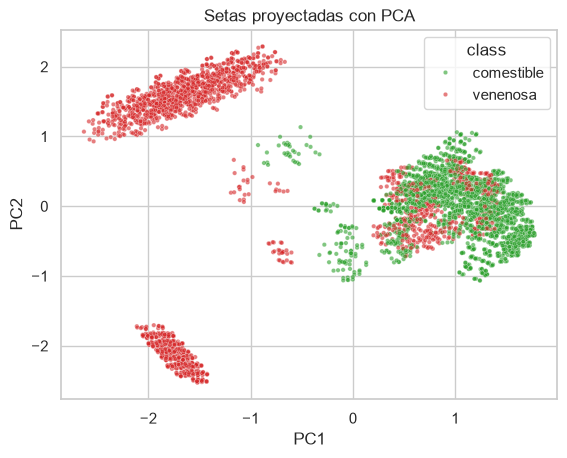

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train)  # cada seta pasa a ser un punto (PC1, PC2)
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))

# Coloreamos con la etiqueta SOLO para mirar: PCA no la ha usado
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train.map({0: "comestible", 1: "venenosa"}),
                hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Setas proyectadas con PCA")
plt.show()

In [17]:
# ¿Qué hay DENTRO de PC1? Sus pesos: cuánto aporta cada una de las 115 columnas
pesos_pc1 = pd.Series(pca.components_[0], index=X_train.columns)
print("Columnas que participan en PC1:", (pesos_pc1 != 0).sum(), "de", X_train.shape[1])
pesos_pc1.reindex(pesos_pc1.abs().sort_values(ascending=False).index).head(5).round(2)

Columnas que participan en PC1: 115 de 115


ring-type_p                   0.29
bruises_t                     0.27
bruises_f                    -0.27
stalk-surface-above-ring_k   -0.26
stalk-surface-below-ring_k   -0.25
dtype: float64

In [18]:
# 📖 Idea del primer libro: ¿cuántas componentes guardan el 95 % de la varianza en NUESTRAS setas?
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train)  # un número entre 0 y 1 = % de varianza
print(f"Para guardar el 95 % de la varianza hacen falta {pca95.n_components_} de {X_train.shape[1]} columnas")

Para guardar el 95 % de la varianza hacen falta 40 de 115 columnas


Con solo 2 componentes ya se ven **zonas bastante separadas**: hay estructura que el clustering podrá encontrar.

### Línea base supervisada: Random Forest

**Por qué aquí, si el taller es no supervisado:** es una **regla para medir**. Usamos la etiqueta *solo* para saber **cuánta información hay en los datos**.

- Si un modelo **con** etiqueta acierta casi siempre → las columnas **sí** separan comestibles de venenosas → el clustering tiene algo que encontrar.
- **Random Forest** = muchos árboles de decisión que **votan**; se entrena con `train` y se examina con `test` (datos que no ha visto).

> 📖 **En los libros**
>
> - **Primer libro:** un `DummyClassifier` que responde siempre *«no es un 5»* acierta **más del 90 %** en MNIST, solo porque los 5 son ~10 %. Por eso hace falta una **línea base tonta**: un 90 % puede no significar nada.
> - **Segundo libro:** *«predecir leucemia solo si el bebé se llama Luke»* acierta >98 %… porque la enfermedad es rara. **La precisión sola engaña.**
> - Ambos: un Random Forest son **árboles entrenados con muestras distintas que votan**.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)  # 100 árboles que votan
rf.fit(X_train, y_train)                    # aprende con train
acc = accuracy_score(y_test, rf.predict(X_test))  # examen con test (datos que no ha visto)
print(f"Accuracy con las {X_train.shape[1]} columnas: {acc:.3f}")

Accuracy con las 115 columnas: 1.000


In [20]:
# 📖 Idea de los libros: comparar con un modelo 'tonto' que siempre dice la clase más frecuente
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Modelo tonto: {accuracy_score(y_test, dummy.predict(X_test)):.3f}  vs  Random Forest: {acc:.3f}")

Modelo tonto: 0.514  vs  Random Forest: 1.000


### ¿Cuántas componentes PCA bastan?

Probamos a reducir a *n* componentes y volvemos a entrenar el Random Forest. Buscamos el **mínimo *n*** que mantiene la precisión.

> 📖 **En el primer libro** se hace lo mismo con MNIST: un `Pipeline` de **PCA + Random Forest** busca el mejor nº de componentes y pasa de **784 a ~57** sin perder precisión. Es el equilibrio **velocidad ↔ precisión**: si quitas demasiadas, el modelo pierde información.

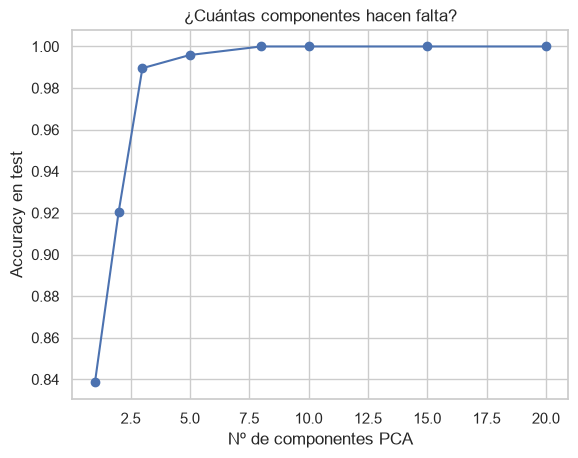

{1: 0.838, 2: 0.921, 3: 0.99, 5: 0.996, 8: 1.0, 10: 1.0, 15: 1.0, 20: 1.0}

In [21]:
n_features = [1, 2, 3, 5, 8, 10, 15, 20]  # valores de n a probar
scores = []

for n in n_features:
    pca_n = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train)  # PCA aprende SOLO con train
    rf_n = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf_n.fit(pca_n.transform(X_train), y_train)
    scores.append(accuracy_score(y_test, rf_n.predict(pca_n.transform(X_test))))

plt.plot(n_features, scores, marker="o")
plt.xlabel("Nº de componentes PCA"); plt.ylabel("Accuracy en test")
plt.title("¿Cuántas componentes hacen falta?")
plt.show()
dict(zip(n_features, [round(s, 3) for s in scores]))

### t-SNE: reducción **no lineal** para visualizar

**Qué es:** *t-Distributed Stochastic Neighbor Embedding* — coloca cada dato en un mapa 2D para que **los vecinos sigan siendo vecinos**.

- *Imagina una fiesta:* t-SNE acomoda a los invitados en un salón para que **los amigos queden juntos**.
- **PCA** conserva la forma general y sus ejes se interpretan; **t-SNE** conserva los vecinos cercanos, pero sus **ejes y distancias entre grupos no significan nada**.
- ⚠️ **Solo sirve para mirar**, no para sacar conclusiones exactas (y no sabe colocar datos nuevos). Es lento: usamos una muestra.

![t-SNE](assets/taller/f03-tsne.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En el primer libro**
>
> - t-SNE es **casi solo para visualizar**: *no* se usa como paso previo para entrenar un modelo.
> - Ejemplo: 5.000 dígitos de **MNIST** (784 píxeles) en 2D → **10 nubes separadas**, una por dígito, sin decirle cuál es cuál. Igual que nuestras setas.
> - Con el *rollo suizo* (la espiral 3D): **Isomap** lo desenrolla, pero **t-SNE lo rompe en trozos**: exagera los grupos locales y pierde la forma global.

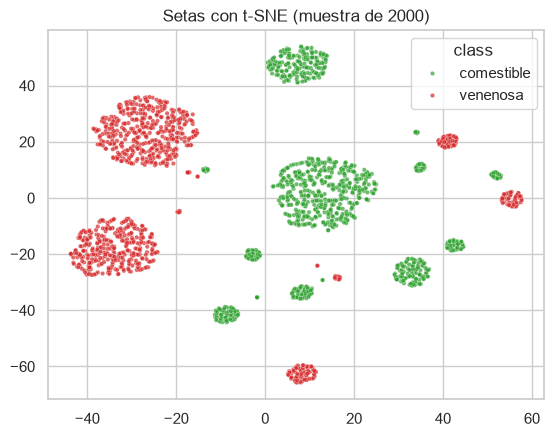

In [22]:
from sklearn.manifold import TSNE

muestra = X_train.sample(2000, random_state=RANDOM_STATE)  # t-SNE es lento: 2000 setas bastan
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(muestra)

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1],
                hue=y_train.loc[muestra.index].map({0: "comestible", 1: "venenosa"}), hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.7)
plt.title("Setas con t-SNE (muestra de 2000)")
plt.show()

### PCA o t-SNE: ¿cuál uso?

**PCA** para **reducir columnas**; **t-SNE** para **explorar grupos**. Se pueden usar juntos: primero PCA para quitar ruido y luego t-SNE para dibujar.

![PCA o t-SNE](assets/taller/f03-pca-vs-tsne.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> **Resumen fase 03:** con **PCA** se ven zonas separadas; **Random Forest** acierta ≈ 100 % (los datos tienen mucha información) y **~10 componentes PCA** bastan para mantenerlo. **t-SNE** muestra grupos más compactos, pero solo sirve para visualizar.

## Fase 04 · Modelado: buscar grupos sin mirar la etiqueta

**Objetivo:** probar **4 algoritmos de clustering** (K-Means, Aglomerativo, GMM y DBSCAN) y ver qué grupos encuentran **solos**. La etiqueta `y` **no se usa** para entrenar.

### Preparar los datos: PCA a 10 componentes

En la fase 03 vimos que con **~10 componentes** ya está casi toda la información útil. Trabajamos sobre esa versión reducida (`X_red`): **quita ruido y hace los algoritmos más rápidos**.

Usamos **todo `X`** (no solo train): en clustering no hay que predecir nada nuevo, queremos agrupar todas las setas.

In [23]:
# Reducimos las 115 columnas one-hot a 10 componentes
X_red = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X)
X_red.shape

(8124, 10)

### K-Means: grupos alrededor de un centro

**Qué es:** eliges **k** (cuántos grupos). El algoritmo pone k centros, mete cada seta en el **centro más cercano**, mueve cada centro al **promedio** de su grupo y repite hasta que nada cambia.

- *Analogía:* k repartidores en una ciudad; cada casa va al repartidor más cercano.
- **Problema:** hay que decirle k. Para elegirlo usamos dos pistas:
  - **Codo (inercia):** cuánto se alejan los puntos de su centro. **Siempre baja** al subir k; buscamos dónde la curva **se dobla**.
  - **Silueta:** de −1 a 1, **cuánto mejor está cada punto en su grupo que en el vecino**. Más alta = mejor.

![K-Means](assets/taller/f04-kmeans.png)

![Método del codo](assets/taller/f04-codo.png)

![Silueta](assets/taller/f04-silueta.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** 5 grupos inventados (*blobs*). El **codo** sale en **k = 4** y la **silueta** más alta también (0,689)… pero la respuesta buena es **k = 5**: lo descubre mirando el **diagrama de silueta** (con k = 4 un grupo es enorme). **Las métricas son pistas**, como nos pasa con las setas.
> - **Segundo libro:** dónde organizar quedadas para **20 usuarios** según su barrio. El error total baja de **>15.000** (k = 1) a **4.400** (k = 2) y a **1.200** (k = 3); después casi no baja → **codo claro en k = 3**. Avisa: si k = nº de puntos, el error es 0, por eso no se elige el k con menos error.

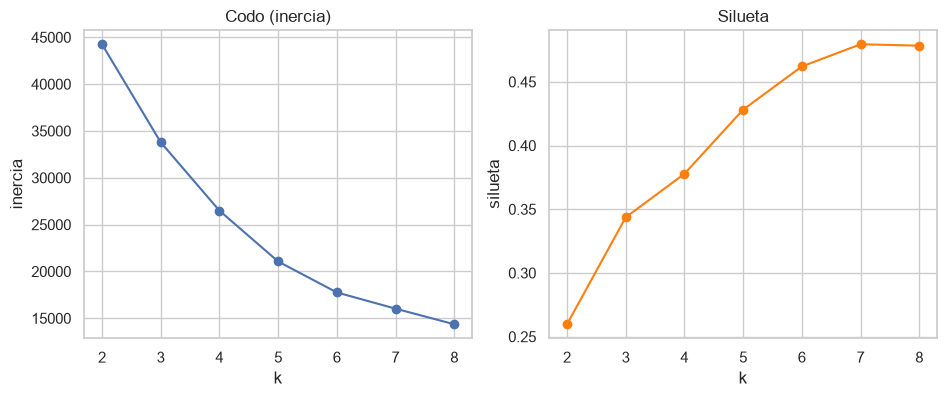

,k,inercia,silueta
0,2,44251.650,0.260
1,3,33784.320,0.344
2,4,26490.413,0.378
3,5,21060.524,0.428
4,6,17755.768,0.462
5,7,16023.219,0.479
6,8,14357.278,0.478


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inercias, siluetas = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_red)
    inercias.append(km.inertia_)                      # codo: distancia total a los centros
    siluetas.append(silhouette_score(X_red, km.labels_,
                                     sample_size=3000, random_state=RANDOM_STATE))  # muestra: más rápido

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_values, inercias, "o-"); ax[0].set(title="Codo (inercia)", xlabel="k", ylabel="inercia")
ax[1].plot(k_values, siluetas, "o-", color="tab:orange"); ax[1].set(title="Silueta", xlabel="k", ylabel="silueta")
plt.show()
pd.DataFrame({"k": k_values, "inercia": inercias, "silueta": siluetas}).round(3)

**Lectura honesta:** aquí el codo **no es claro** y la silueta **sigue subiendo** con k (hay muchos subtipos de setas). Las métricas son **pistas, no la respuesta**: la decide también **la pregunta de negocio**. Nuestra pregunta es *«¿se separan solas en 2 grupos (comestible / venenosa)?»*, así que probamos **k = 2**.

In [25]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_red)
clusters_km = kmeans.labels_

# Cuántas setas hay en cada cluster
print(pd.Series(clusters_km).value_counts().sort_index())

# Solo para MIRAR (no para entrenar): ¿qué hay dentro de cada cluster?
pd.crosstab(clusters_km, y.map({0: "comestible", 1: "venenosa"}),
            rownames=["cluster"], colnames=["etiqueta real"])

0    4969
1    3155
Name: count, dtype: int64


etiqueta real,comestible,venenosa
cluster,,
0,4153,816
1,55,3100


### Aglomerativo (jerárquico): un árbol de grupos

**Qué es:** cada seta empieza **sola**; en cada paso se **unen los dos grupos más cercanos**, hasta que todo es un grupo. El resultado es un **árbol (dendrograma)**.

- *Analogía:* un árbol genealógico: personas → parejas → familias → clan.
- **No hay que elegir k al principio:** se elige después, **cortando el árbol** a una altura. Cuanto más alta la unión, más distintos eran los grupos.
- Con `method="ward"` une los grupos que menos aumentan la dispersión (parecido a K-Means).

![Cómo leer un dendrograma](assets/taller/f04-dendrograma.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Segundo libro:** los mismos **20 usuarios**: el árbol hace **19 uniones** hasta tener un solo grupo. **Cortar arriba** da **2 grupos (6 y 14 usuarios)**; cortar un poco más abajo, 3.
> - **Primer libro:** visitantes de un blog: un grupo de **40 % adolescentes** (después de clase) y otro de **20 % adultos** (fines de semana), que el jerárquico puede **subdividir** en grupos más pequeños.

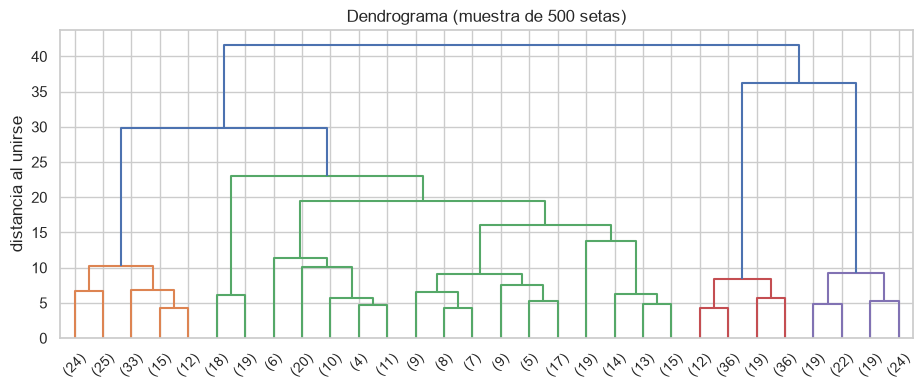

0    3024
1    5100
Name: count, dtype: int64

In [26]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# El dendrograma con 8124 setas no se lee: usamos una muestra de 500
rng = np.random.default_rng(RANDOM_STATE)
muestra = X_red[rng.choice(len(X_red), size=500, replace=False)]
arbol = linkage(muestra, method="ward")

plt.figure(figsize=(11, 4))
dendrogram(arbol, truncate_mode="lastp", p=30)   # enseña solo las 30 últimas uniones
plt.title("Dendrograma (muestra de 500 setas)"); plt.ylabel("distancia al unirse")
plt.show()

# Cortamos el árbol en 2 grupos sobre TODOS los datos
clusters_ag = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_red)
pd.Series(clusters_ag).value_counts().sort_index()

### GMM (mezcla de gaussianas): grupos con probabilidad

**Qué es:** supone que cada grupo es una **campana (gaussiana)** que puede ser **alargada o inclinada**, no solo redonda como en K-Means.

- **Diferencia clave:** K-Means da a cada seta **un solo grupo**; GMM le da **una probabilidad por grupo** (p. ej. 70 % grupo 0, 30 % grupo 1). Es una **asignación probabilística**.
- *Analogía:* las estaturas de un grupo: muchas cerca de la media, pocas en los extremos.

![GMM](assets/taller/f04-gmm.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** 1.250 puntos en **3 elipses** (500 / 500 / 250). GMM descubre sus pesos (≈ 0,40 / 0,21 / 0,39) y para cada punto da probabilidades como **97,7 %** de un grupo. Además sirve para **anomalías**: marca el **2 %** de puntos en las zonas de menos densidad. Con las flores **Iris** solo falla **5 de 150**.
> - **Segundo libro:** no trata GMM (solo K-Means y jerárquico).

In [27]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=RANDOM_STATE).fit(X_red)
clusters_gmm = gmm.predict(X_red)          # el grupo más probable
probs = gmm.predict_proba(X_red)            # probabilidad de cada grupo

print(pd.Series(clusters_gmm).value_counts().sort_index())
print("Setas con duda (ningún grupo > 90 %):", (probs.max(axis=1) < 0.9).sum())
pd.DataFrame(probs[:5], columns=["P(grupo 0)", "P(grupo 1)"]).round(3)

0    5073
1    3051
Name: count, dtype: int64
Setas con duda (ningún grupo > 90 %): 34


,P(grupo 0),P(grupo 1)
0,1.0,0.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0


### DBSCAN: grupos por densidad (y la distancia importa)

**Qué es:** un grupo es una **zona con muchos puntos juntos**. No hay que elegir k. Tiene **2 parámetros**:

- **`eps`:** la distancia máxima para considerar a dos puntos **vecinos** (el radio).
- **`min_samples`:** cuántos vecinos hacen falta para que un punto sea **núcleo** de un grupo.
- Quien queda lejos de todos es **ruido** (etiqueta **−1**).

![DBSCAN](assets/taller/f04-dbscan.png)

**La distancia importa:** nuestras setas son **0/1**. La distancia **euclídea** mide «cuánto se diferencian los números»; la de **Jaccard** mide «de las características que tiene alguna de las dos, **cuántas comparten**». Para datos 0/1, Jaccard tiene más sentido.

![One-hot y Jaccard](assets/taller/f04-jaccard.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** dos **lunas** de 1.000 puntos. Con **`eps = 0.05`** salen **7 grupos** y mucho ruido; con **`eps = 0.20`**, las **2 lunas** casi sin ruido. **Un pequeño cambio de `eps` lo cambia todo**, igual que con nuestras setas.
> - **Ninguno de los dos libros** usa Jaccard: el segundo, para vectores 0/1 (intereses de usuarios), usa la similitud **coseno**. La idea es la misma: **con datos 0/1, la distancia euclídea no es la mejor**.

No sabemos qué `eps` usar, así que **probamos varios** y contamos cuántos grupos salen.

In [28]:
from sklearn.cluster import DBSCAN

def resumen_dbscan(labels):
    n_grupos = len(set(labels)) - (1 if -1 in labels else 0)   # el -1 (ruido) no es un grupo
    return n_grupos, (labels == -1).sum()

# 1) Distancia EUCLÍDEA sobre X_red
for eps in [0.5, 1, 1.5, 2, 3]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_red)
    print(f"euclídea eps={eps:<4} -> grupos: %3d  ruido: %d" % resumen_dbscan(labels))

euclídea eps=0.5  -> grupos: 130  ruido: 690
euclídea eps=1    -> grupos:  36  ruido: 24


euclídea eps=1.5  -> grupos:   6  ruido: 0


euclídea eps=2    -> grupos:   4  ruido: 0


euclídea eps=3    -> grupos:   1  ruido: 0


In [29]:
# 2) Distancia de JACCARD sobre el one-hot original (True/False)
X_bin = X.values.astype(bool)
for eps in [0.2, 0.3, 0.4, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=10, metric="jaccard").fit_predict(X_bin)
    print(f"jaccard  eps={eps:<4} -> grupos: %3d  ruido: %d" % resumen_dbscan(labels))

clusters_db = DBSCAN(eps=0.4, min_samples=10, metric="jaccard").fit_predict(X_bin)  # lo guardamos para la fase 05

jaccard  eps=0.2  -> grupos:  19  ruido: 16


jaccard  eps=0.3  -> grupos:  14  ruido: 16


jaccard  eps=0.4  -> grupos:   5  ruido: 8


jaccard  eps=0.5  -> grupos:   3  ruido: 5


**Lectura:** con **euclídea**, `eps` pequeño **rompe** las setas en decenas de trocitos (130 grupos y 690 de ruido) y `eps` grande lo junta **todo en 1 grupo**. Con **Jaccard** el número de grupos baja **poco a poco** (19 → 14 → 5 → 3) y casi no hay ruido. Nos quedamos con `eps = 0.4` (5 grupos).

⚠️ Ninguno da exactamente 2 grupos: DBSCAN no busca «comestible / venenosa», busca **zonas densas** (subtipos de setas). ¿Cuál agrupa mejor? Lo **mediremos** en la fase 05 con la etiqueta.

> **Resumen fase 04:** con `X_red` (PCA a 10), **K-Means**, **Aglomerativo** y **GMM** con **k = 2** dan dos grupos de tamaño parecido (~5000 / ~3100). El **codo y la silueta no deciden solos**: k = 2 sale de la pregunta. **GMM** da probabilidades en vez de un grupo fijo. **DBSCAN** con euclídea es todo o nada (trocitos o 1 grupo); con **Jaccard** cambia poco a poco y con `eps = 0.4` da 5 grupos casi sin ruido.

## Fase 05 · Evaluación: ¿los grupos sirven?

**Objetivo:** medir **qué tan buenos** son los grupos de la fase 04. Ahora sí usamos la etiqueta `y`, pero **solo para comprobar**, nunca para entrenar.

### Dos tipos de métricas

| Tipo | Métrica | Cómo se lee | ¿Usa la etiqueta? |
|---|---|---|---|
| **Internas** | **Silueta** | de −1 a 1, **más alto = mejor** | ❌ |
| | **Davies-Bouldin** | **más bajo = mejor** (grupos compactos y lejanos entre sí) | ❌ |
| | **Calinski-Harabasz** | **más alto = mejor** (separación entre grupos / dispersión dentro) | ❌ |
| **Externas** | **ARI** | **0 = azar, 1 = idéntico** a la etiqueta | ✅ |
| | **NMI** | **0 = no dice nada** de la etiqueta, **1 = la explica entera** | ✅ |

- Las **internas** miden si los grupos están **bien formados** (se pueden usar siempre).
- Las **externas** miden si los grupos **coinciden con la realidad** (solo si tenemos etiqueta, como aquí).

![¿Cómo sé si los clusters sirven?](assets/taller/f05-metricas.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** no usa ARI, pero **valida igual que nosotros**: compara el GMM con las especies reales de las flores **Iris** y solo falla **5 de 150** (96,7 %). Y un uso práctico: con **1.797 dígitos** hace **50 clusters**, etiqueta **a mano solo 1 dígito por cluster** y copia esa etiqueta al resto del grupo → un modelo pasa de **75,8 % a 86,9 %** de acierto. El clustering **ahorra etiquetar**.
> - **Segundo libro:** avisa de que *«normalmente no hay un agrupamiento correcto»* y que *«los clusters no se etiquetan solos»*: el nombre de cada grupo lo pone una persona (lo haremos con las Tarjetas).

In [30]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

# DBSCAN euclídea con eps=1.5 (el que daba 6 grupos en la fase 04) para compararlo
clusters_db_euc = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_red)

def evaluar(nombre, labels):
    fila = {"algoritmo": nombre,
            "grupos": len(set(labels)) - (1 if -1 in labels else 0)}
    # Internas: todas sobre X_red, para comparar en igualdad
    fila["silueta"] = silhouette_score(X_red, labels, sample_size=3000, random_state=RANDOM_STATE)
    fila["davies_bouldin"] = davies_bouldin_score(X_red, labels)
    fila["calinski_harabasz"] = calinski_harabasz_score(X_red, labels)
    # Externas: comparan con la etiqueta real (SOLO para validar)
    fila["ARI"] = adjusted_rand_score(y, labels)
    fila["NMI"] = normalized_mutual_info_score(y, labels)
    return fila

tabla = pd.DataFrame([
    evaluar("K-Means", clusters_km),
    evaluar("Aglomerativo", clusters_ag),
    evaluar("GMM", clusters_gmm),
    evaluar("DBSCAN euclídea", clusters_db_euc),
    evaluar("DBSCAN Jaccard", clusters_db),
]).round(3)
tabla

,algoritmo,grupos,silueta,davies_bouldin,calinski_harabasz,ARI,NMI
0,K-Means,2,0.260,1.693,2564.691,0.617,0.566
1,Aglomerativo,2,0.257,1.696,2503.625,0.609,0.594
2,GMM,2,0.256,1.701,2500.017,0.599,0.566
3,DBSCAN euclídea,6,0.357,1.071,2304.340,0.374,0.464
4,DBSCAN Jaccard,5,0.236,1.032,1381.963,0.443,0.454


**Lectura:**

- **K-Means, Aglomerativo y GMM** (k = 2) dan casi lo mismo: **ARI ≈ 0,6 y NMI ≈ 0,57**. Sin ver la etiqueta, recuperan **buena parte** de comestible / venenosa (el Random Forest supervisado llegaba al 100 %).
- **DBSCAN euclídea** tiene la **mejor silueta (0,357) y Davies-Bouldin**, pero el **peor ARI (0,374)**. ⚠️ **Grupos bien formados ≠ grupos que coinciden con la pregunta**: encuentra 6 subtipos compactos, no las 2 clases.
- **DBSCAN Jaccard** (0,443) gana a la euclídea en ARI: la distancia pensada para datos 0/1 **sí ayuda**.

### ¿Por qué ARI y no «% de aciertos»?

Los números de los clusters son **nombres arbitrarios**: K-Means puede llamar «0» a las comestibles o a las venenosas. El ARI **solo mira si las setas que van juntas en la realidad van juntas en los clusters**, da igual cómo se llamen. Lo comprobamos:

In [31]:
# Cambiamos los nombres de los clusters: 0 <-> 1
clusters_km_cambiado = 1 - clusters_km

print("ARI original:          ", round(adjusted_rand_score(y, clusters_km), 3))
print("ARI con nombres al revés:", round(adjusted_rand_score(y, clusters_km_cambiado), 3))

# Y un reparto al AZAR da ARI ~ 0
azar = np.random.default_rng(RANDOM_STATE).integers(0, 2, size=len(y))
print("ARI de un reparto al azar:", round(adjusted_rand_score(y, azar), 3))

ARI original:           0.617
ARI con nombres al revés: 0.617
ARI de un reparto al azar: 0.0


#### Ejemplo de juguete: 4 setas y 3 compañeros

El ARI **no mira los números ni el orden**: mira **quién comparte grupo con quién**.

| Seta | Realidad | Tú | Compañero 2 (nombres al revés) | Compañero 3 (0 1 0 1) |
|---|---|---|---|---|
| A | comestible | 0 | 1 | 0 |
| B | comestible | 0 | 1 | 1 |
| C | venenosa | 1 | 0 | 0 |
| D | venenosa | 1 | 0 | 1 |

- **Tú** y el **compañero 2** hacéis **los mismos grupos** ({A, B} y {C, D}); solo cambia el nombre.
- El **compañero 3** junta {A, C} y {B, D}: **cada grupo mezcla** una comestible y una venenosa.

In [32]:
real = ["comestible", "comestible", "venenosa", "venenosa"]   # setas A, B, C, D

casos = {"Tú":                  [0, 0, 1, 1],
         "Compañero 2 (al revés)": [1, 1, 0, 0],
         "Compañero 3 (0 1 0 1)":  [0, 1, 0, 1]}

for nombre, clusters in casos.items():
    aciertos = np.mean([(c == 0) == (r == "comestible") for c, r in zip(clusters, real)])  # «0 = comestible»
    print(f"{nombre:24} % aciertos: {aciertos:4.0%}   ARI: {adjusted_rand_score(real, clusters):5.2f}")

Tú                       % aciertos: 100%   ARI:  1.00
Compañero 2 (al revés)   % aciertos:   0%   ARI:  1.00
Compañero 3 (0 1 0 1)    % aciertos:  50%   ARI: -0.50


### Verlo: clusters de K-Means frente a la etiqueta real

Mismo PCA 2D, dos colores distintos: a la izquierda lo que **encontró K-Means**, a la derecha **la verdad**.

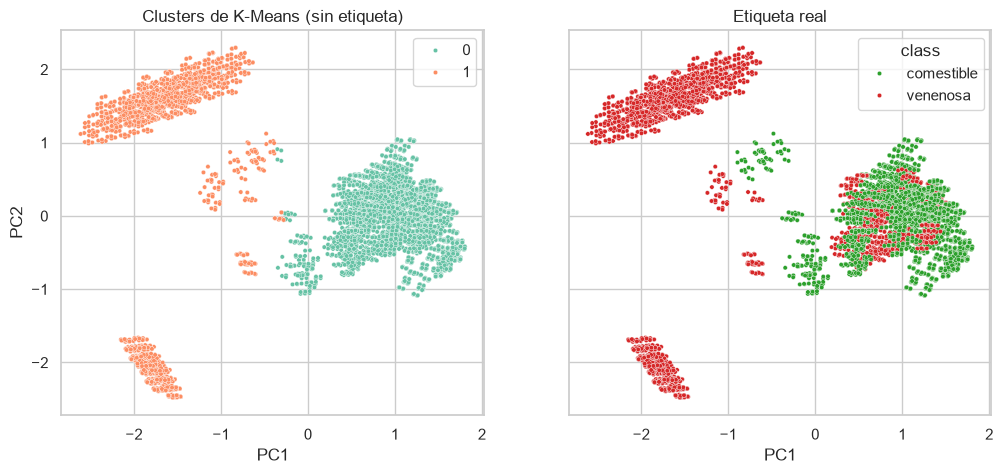

In [33]:
X_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=clusters_km, palette="Set2", s=10, ax=ax[0])
ax[0].set(title="Clusters de K-Means (sin etiqueta)", xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y.map({0: "comestible", 1: "venenosa"}),
                hue_order=["comestible", "venenosa"],
                palette={"comestible": "tab:green", "venenosa": "tab:red"}, s=10, ax=ax[1])
ax[1].set(title="Etiqueta real", xlabel="PC1")
plt.show()

Se parecen mucho: K-Means ha visto la estructura **sin la etiqueta**. Los fallos son sobre todo las **816 venenosas** que K-Means metió en el grupo de las comestibles (y 55 al revés), como vimos en la tabla de la fase 04.

### ¿Qué algoritmo uso?

![Comparación de algoritmos](assets/taller/f05-comparativa.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

**Regla práctica:** empieza por **K-Means** (rápido y simple); si los grupos tienen formas raras o hay atípicos, prueba **DBSCAN**; si importa la probabilidad, **GMM**.

> **Resumen fase 05:** las métricas **externas** (ARI, NMI) comparan con la etiqueta; las **internas** (silueta ↑, Davies-Bouldin ↓, Calinski-Harabasz ↑) solo miran la forma de los grupos. **K-Means k = 2: ARI ≈ 0,62 · NMI ≈ 0,57**, Aglomerativo y GMM casi igual. **DBSCAN euclídea** tiene la mejor silueta pero el peor ARI: **grupos bonitos no son grupos útiles**. Jaccard mejora a la euclídea (0,44 vs 0,37). El ARI no depende del nombre de los clusters.

## Fase 06 · Interpretación: anomalías y conclusiones

**Objetivo:** buscar las setas **raras** (Isolation Forest), **revisar** si Jaccard ayudó de verdad y **cerrar las conclusiones** de la Parte 1.

### Isolation Forest: encontrar lo raro

**Qué es:** un bosque de árboles que **corta los datos al azar** (elige una columna y un punto de corte cualquiera) una y otra vez, hasta dejar **cada punto solo**.

- Un punto **normal** está rodeado de muchos otros: hacen falta **muchos cortes** para aislarlo.
- Un punto **raro** está apartado: se aísla con **pocos cortes**. Eso es una **anomalía**.
- **`contamination`**: qué **proporción** esperamos de anomalías (aquí 5 %). `predict` devuelve **−1 = anomalía** y **1 = normal**.
- *Analogía:* en el juego de «¿Quién es quién?», al personaje con sombrero, gafas y bigote rojo lo encuentras en 2 preguntas; al más normal te cuesta muchas.

*(Las diapositivas no tienen Isolation Forest: la explicación sale del primer libro.)*

> 📖 **En los libros**
>
> - **Primer libro:** explica Isolation Forest como arriba (cortes al azar; las anomalías se aíslan **en menos pasos**). Y da otras formas de buscar lo raro que ya conocemos: con **GMM**, marcar el **2 %** de puntos en las zonas de menos densidad (fábrica con un 2 % de piezas defectuosas); con **DBSCAN**, el **ruido (−1)**.
> - **Segundo libro:** no trata Isolation Forest, pero da un ejemplo de por qué importan los raros: en una red social, una **cuenta de prueba** con 100 amigos y 1 minuto al día **estropeaba** la relación amigos ↔ minutos; al quitarla, la correlación vuelve a **0,57**.

In [34]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE).fit(X_red)
es_anomalia = iso.predict(X_red) == -1          # -1 = anomalía

print(f"Anomalías: {es_anomalia.sum()} de {len(X_red)} ({es_anomalia.mean():.1%})")
# Solo para mirar: ¿las raras son comestibles o venenosas?
y[es_anomalia].map({0: "comestible", 1: "venenosa"}).value_counts(normalize=True).round(2)

Anomalías: 407 de 8124 (5.0%)


class
comestible    0.8
venenosa      0.2
Name: proportion, dtype: float64

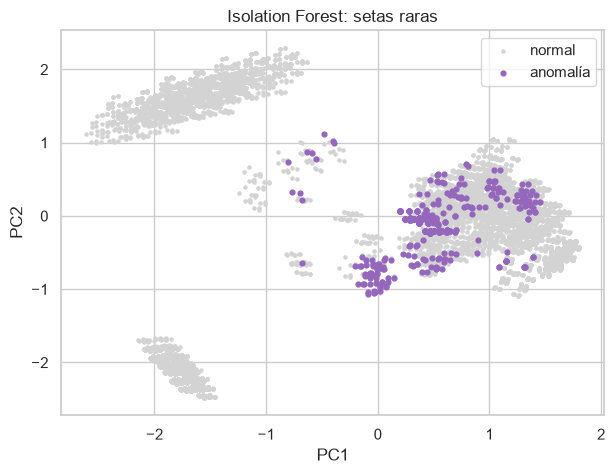

In [35]:
# Las pintamos sobre el PCA 2D de la fase 05
plt.figure(figsize=(7, 5))
plt.scatter(X_2d[~es_anomalia, 0], X_2d[~es_anomalia, 1], s=5, c="lightgray", label="normal")
plt.scatter(X_2d[es_anomalia, 0], X_2d[es_anomalia, 1], s=12, c="tab:purple", label="anomalía")
plt.title("Isolation Forest: setas raras"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.show()

**¿Qué las hace raras?** Comparamos, columna a columna, el **% de setas raras** que tienen cada característica con el **% del resto**:

In [36]:
comparacion = pd.DataFrame({
    "% en raras": X[es_anomalia].mean() * 100,
    "% en el resto": X[~es_anomalia].mean() * 100,
})
comparacion["diferencia"] = comparacion["% en raras"] - comparacion["% en el resto"]
comparacion.sort_values("diferencia", ascending=False).head(6).round(1)

,% en raras,% en el resto,diferencia
stalk-shape_e,91.6,40.7,50.9
gill-attachment_a,47.4,0.2,47.2
stalk-color-below-ring_o,47.2,0.0,47.2
stalk-color-above-ring_o,47.2,0.0,47.2
habitat_l,49.6,8.2,41.5
ring-type_p,87.5,46.8,40.7


**Lectura:** las raras son sobre todo **comestibles (80 %)** con **combinaciones poco frecuentes**: casi la mitad tiene el **tallo naranja** (`stalk-color_o`: 47 % frente a **0 %** en el resto) y **láminas adheridas** (`gill-attachment_a`: 47 % frente a 0,2 %), y la mitad crece entre **hojas** (`habitat_l`: 50 % frente a 8 %). **No son errores:** son **subtipos poco comunes**.

> Una anomalía **no es automáticamente un error**: puede ser un error de datos, un fraude… o simplemente **algo poco común pero real**. Hay que **mirarla** antes de borrarla.

### Revisamos una conclusión: ¿Jaccard ayudó de verdad?

En la fase 05 vimos *DBSCAN Jaccard (ARI 0,443) > DBSCAN euclídea (0,374)*. Pero **comparamos dos cosas a la vez**: la euclídea iba sobre `X_red` (**PCA a 10**) y Jaccard sobre el **one-hot completo (115)**. Para ser justos, cambiamos **solo una cosa**: euclídea **también** sobre el one-hot completo.

In [37]:
print("Unos por fila:", X.sum(axis=1).unique())   # ¿cuántas características marcadas tiene cada seta?

labels_jac = DBSCAN(eps=0.4, min_samples=10, metric="jaccard").fit_predict(X_bin)
labels_euc = DBSCAN(eps=3.2, min_samples=10).fit_predict(X.values.astype(float))  # eps equivalente

print("ARI Jaccard              :", round(adjusted_rand_score(y, labels_jac), 3))
print("ARI euclídea (one-hot)   :", round(adjusted_rand_score(y, labels_euc), 3))
print("¿Mismos grupos? (ARI entre ellos):", round(adjusted_rand_score(labels_jac, labels_euc), 3))

Unos por fila: [21]


ARI Jaccard              : 0.443
ARI euclídea (one-hot)   : 0.443
¿Mismos grupos? (ARI entre ellos): 1.0


**¡Sorpresa!** Dan **exactamente los mismos grupos**. ¿Por qué? Cada seta tiene **exactamente 21 unos** (un valor por cada variable). Así, contar «cuántas características comparten» (Jaccard) o «en cuántas se diferencian» (euclídea) es **lo mismo**. La mejora de la fase 05 venía de **no reducir con PCA**, no de Jaccard.

🧠 **Lección:** al comparar, **cambia una sola cosa cada vez**.

**Entonces, ¿cuándo sí gana Jaccard?** Cuando las filas tienen **distinto número de unos** (cestas de la compra, intereses, etiquetas). Jaccard **ignora los ceros compartidos**: que dos clientes **no** compren lo mismo no los hace parecidos.

![One-hot y Jaccard](assets/taller/f04-jaccard.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

In [38]:
from scipy.spatial.distance import euclidean, jaccard

#                pan leche huevos fruta café  té
A = np.array([1,  0,    0,     0,    0,  0])   # solo pan
B = np.array([0,  1,    0,     0,    0,  0])   # solo leche
C = np.array([1,  1,    1,     1,    0,  0])   # compra grande
D = np.array([1,  1,    1,     0,    1,  0])   # compra grande parecida

print(f"A-B  euclídea: {euclidean(A, B):.2f}   Jaccard: {jaccard(A, B):.2f}   (no comparten nada)")
print(f"C-D  euclídea: {euclidean(C, D):.2f}   Jaccard: {jaccard(C, D):.2f}   (comparten 3 productos)")

A-B  euclídea: 1.41   Jaccard: 1.00   (no comparten nada)
C-D  euclídea: 1.41   Jaccard: 0.40   (comparten 3 productos)


La **euclídea** dice que A-B y C-D están **igual de cerca** (1,41): cuenta como parecido que A y B **no compren** huevos, fruta, café ni té. **Jaccard** ve lo obvio: A y B **no comparten nada** (1,0) y C y D se parecen mucho (0,4).

> 📖 **En los libros**
>
> - **Primer libro:** recuerda que con one-hot, en distancia euclídea, **todas las categorías quedan a la misma distancia** entre sí. El Jaccard aparece con otro nombre, **IoU** (intersección / unión), para medir cuánto se solapan dos recuadros en una imagen.
> - **Segundo libro:** con **15 usuarios** y sus intereses en 0/1 usa la similitud **coseno** (que tampoco cuenta los ceros compartidos): el usuario 0 y el 9 comparten Hadoop, Java y Big Data → **0,57**; el 0 y el 8 solo Big Data → **0,19**.

### 🍄 Conclusiones de la Parte 1 (Setas)

| Pregunta | Respuesta |
|---|---|
| ¿Hay información para separar comestibles y venenosas? | **Sí**: Random Forest (supervisado) acierta el **100 %** |
| ¿Se separan **solas**, sin etiqueta? | **En buena parte**: K-Means k = 2 → **ARI ≈ 0,62 · NMI ≈ 0,57** |
| ¿Qué algoritmo? | K-Means, Aglomerativo y GMM casi empatan; DBSCAN encuentra **subtipos**, no las 2 clases |
| ¿Las métricas internas eligen bien? | **No solas**: la mejor silueta (DBSCAN euclídea) tuvo el peor ARI |
| ¿Jaccard? | En las setas **igual** que la euclídea sobre el one-hot (todas tienen 21 unos); gana con filas de distinto nº de unos |
| ¿Anomalías? | **≈ 5 %**: setas poco comunes (80 % comestibles), **no errores** |

> 📖 *«Los clusters no se etiquetan solos»* (segundo libro): el algoritmo encuentra grupos; **el significado lo pone una persona**. En la Parte 2 (Tarjetas) no habrá etiqueta y esa será **toda** la tarea.

> **Resumen fase 06:** **Isolation Forest** aísla con cortes al azar; lo raro se aísla antes. Con `contamination=0.05` salen **407 setas (5 %)**, sobre todo comestibles con combinaciones poco frecuentes: **raro ≠ error**. Revisando la fase 05, **Jaccard = euclídea** en las setas porque todas tienen 21 unos: la mejora venía de no usar PCA (**cambia una cosa cada vez**). Jaccard gana cuando las filas tienen distinto nº de unos, porque **ignora los ceros compartidos**.